# Projet Leyenda — Deliverable 1: Binary classification (photo vs non-photo)

**Team:** Haytam El hilali / Felipe Lobos / Fernanda Gentil 

TouNum wants to caption photographs automatically. Its digitized archives also contain scanned text, diagrams, drawings and paintings, which must not be sent to the captioning step. This notebook builds the first block of the pipeline: a neural network that sorts the images into two classes, **photo** and **not a photo**.

We use a convolutional neural network (CNN), adapted to our two classes and to the five datasets supplied by TouNum (*Photo*, *Text*, *Sketch*, *Schematics* and *Painting*).

| # | Deliverable requirement | Section |
|---|---|---|
| 1 | TensorFlow code and architecture diagram, with the network parameters, the loss function and the optimization algorithm | 1 |
| 2 | Graph of the training error, the test error and the accuracy on both sets | 2 |
| 3 | Analysis of the results: bias / variance trade-off | 3 |
| 4 | Methods to improve the bias / variance trade-off | 4 |

## 1. TensorFlow code and network architecture

### 1.1 Libraries

We work mainly with `keras`, the deep learning library integrated into `tensorflow`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pathlib
import warnings
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential

warnings.filterwarnings("ignore")   # hides the non-essential warnings so the outputs stay readable
print("TensorFlow:", tf.__version__)

TensorFlow: 2.22.0-rc0


### 1.2 Loading the data and building the datasets



In [2]:
data_dir = pathlib.Path(r"C:\Projet data")

print(data_dir)
for folder in sorted(p for p in data_dir.iterdir() if p.is_dir()):
    n_files = sum(1 for f in folder.rglob("*") if f.is_file())
    print(f"{folder.name:<32} {n_files} files")

C:\Projet data
.git                             87 files
Dataset Livrable 1 - Painting    10000 files
Dataset Livrable 1 - Photo       9993 files
Dataset Livrable 1 - Schematics  10001 files
Dataset Livrable 1 - Sketch      1406 files
Dataset Livrable 1 - Text        10000 files
Dataset Livrable 2 (1)           296 files
leyenda_livrable1                2 files


To begin with, we specify a few parameters for learning:

- the height and width of the images: every image is resized to 180×180 pixels;
- the batch size: the images are given to the network in groups of 32.

In [3]:
image_h = 180
image_w = 180
batch_s = 32

Next, we divide the data into a **training set** and a **test set**. The training set (80 % of the images) is used to train the neural network. The test set (the remaining 20 %) is used to measure its performance on images it has never seen.

We use the function [`tf.keras.utils.image_dataset_from_directory`](https://www.tensorflow.org/api_docs/python/tf/keras/utils/image_dataset_from_directory), which builds a dataset from the image files of a directory. It reads the images of every sub-folder, resizes them and groups them into batches. The same `seed` is given to both calls so that the two sets do not overlap.

**Note:** the learning algorithm must **never** train on the examples of the test set, as this would bias the results.

In [4]:
# The train_set
train_set = tf.keras.utils.image_dataset_from_directory(
  data_dir,
  validation_split=0.2,
  subset="training",
  seed=42,
  image_size=(image_h, image_w),
  batch_size=batch_s
)
# The test_set
test_set = tf.keras.utils.image_dataset_from_directory(
  data_dir,
  validation_split=0.2,
  subset="validation",
  seed=42,
  image_size=(image_h, image_w),
  batch_size=batch_s
)

Found 41696 files belonging to 7 classes.
Using 33357 files for training.
Found 41696 files belonging to 7 classes.
Using 8339 files for validation.


**From five folders to two classes.** The function creates one class per folder, so it finds five classes, numbered from 0 to 4 in alphabetical order. Our problem only has two classes. We therefore replace the label of each image by **1** if it comes from the *Photo* folder and by **0** otherwise.

`ignore_errors()` is a safety: if an image file cannot be decoded, the batch that contains it is skipped instead of stopping the whole training.

In [5]:
folder_names = train_set.class_names
print(folder_names)

photo_index = [i for i, name in enumerate(folder_names) if name.endswith("Photo")][0]

for name, dataset in [("Training set", train_set), ("Test set", test_set)]:
    n_images = len(dataset.file_paths)
    n_photos = sum(pathlib.Path(path).relative_to(data_dir).parts[0] == folder_names[photo_index]
                   for path in dataset.file_paths)
    print(f"{name}: {n_images} images, of which {n_photos} photos ({n_photos / n_images:.0%})")

def to_binary(images, labels):
    # 1 if the image comes from the Photo folder, 0 otherwise
    return images, tf.cast(tf.equal(labels, photo_index), tf.int32)

train_set = train_set.map(to_binary).ignore_errors()
test_set = test_set.map(to_binary).ignore_errors()

class_names = ["not a photo", "photo"]
print(class_names)

['Dataset Livrable 1 - Painting', 'Dataset Livrable 1 - Photo', 'Dataset Livrable 1 - Schematics', 'Dataset Livrable 1 - Sketch', 'Dataset Livrable 1 - Text', 'Dataset Livrable 2 (1)', 'leyenda_livrable1']
Training set: 33357 images, of which 7970 photos (24%)
Test set: 8339 images, of which 2023 photos (24%)
['not a photo', 'photo']


### 1.3 Data exploration and visualization

Let's display a few images of the training set with their class, to see what the two classes look like.

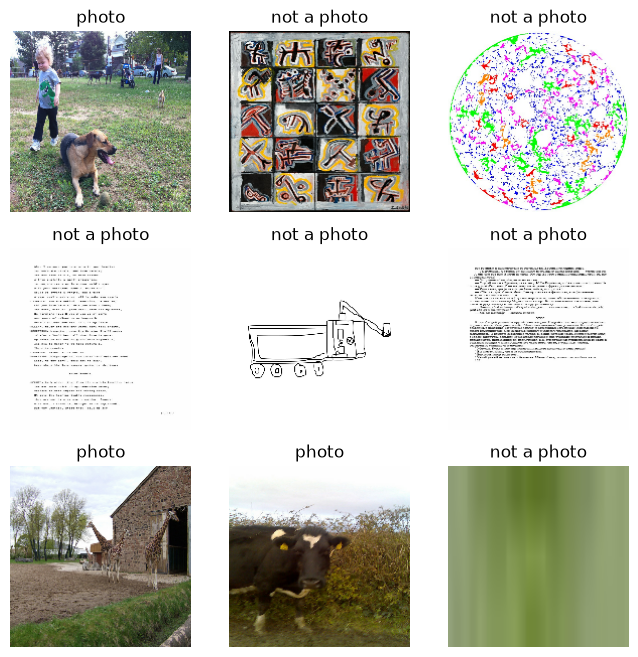

In [6]:
plt.figure(figsize=(8, 8))
for images, labels in train_set.take(1):
    for i in range(9):
        ax =  plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

We also check the size of the data. An element of `train_set` is a batch: a tensor of images of shape (32, 180, 180, 3), that is 32 images of 180×180 pixels with 3 colour channels (RGB), and a tensor of shape (32,) that contains their labels.

In [7]:
images, labels = next(iter(train_set))
print(images.shape)
print(labels.shape)

(32, 180, 180, 3)
(32,)


### 1.4 Setting up the training environment

`Dataset.prefetch()` prepares the next batch while the model is training on the current one, which saves time.

We do not use `Dataset.cache()`, which would keep all the images in memory: with about 41,000 images of 180×180 pixels, they do not fit. The images are read again from the disk at every epoch, and `image_dataset_from_directory` already shuffles them.

In [8]:
AUTOTUNE = tf.data.AUTOTUNE

train_set = train_set.prefetch(buffer_size=AUTOTUNE)
test_set = test_set.prefetch(buffer_size=AUTOTUNE)

### 1.5 The convolutional neural network (CNN) model

The CNN is a neural network architecture created to learn computer vision tasks efficiently. A classical, fully connected network working directly on the pixels would need one weight per pixel and per neuron (180×180×3 = 97,200 inputs), and it would ignore the fact that neighbouring pixels belong together. A CNN slides small filters over the image instead:

- the same filter is reused at every position, so there are far fewer weights;
- the first layers detect **local patterns** (edges, strokes, textures) and the deeper layers combine them into **larger shapes**.

These are the clues that separate a photo from a text scan, a diagram or a drawing.

We start from an empty model, created with [`Sequential`](https://www.tensorflow.org/api_docs/python/tf/keras/Sequential), and add the layers one by one.

In [9]:
num_classes = len(class_names)  # 2 classes, so 2 neurons in the last layer
model = Sequential()

**Normalization.** The value of a pixel is between 0 and 255. The first layer divides it by 255 to bring the input into the interval [0, 1], which makes learning more stable. This is done with the [`layers.Rescaling`](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Rescaling) layer.

In [10]:
model.add(layers.Input(shape=(image_h, image_w, 3)))
model.add(layers.Rescaling(1./255))

**First convolutional block.** A convolutional block is made of two layers:

- the **convolution layer** detects the presence of patterns in the image with the convolution operation. Here it has 16 filters of size (3, 3). With `padding='same'` the output keeps the height and width of the input. Its output goes through the ReLU activation function;
- the **pooling layer** compresses the output of the convolution: it is divided into blocks of 2×2, and only the maximum value of each block is kept. The height and the width are divided by two.

In [11]:
# Convolutional layer
model.add(
    layers.Conv2D(16, 3, padding='same', activation='relu')
)
# Pooling layer
model.add(
    layers.MaxPooling2D()
)

**Rest of the network.** It contains:

- a convolutional block with 32 filters of height and width 3;
- a convolutional block with 64 filters of height and width 3;
- a layer that flattens the previous one into a vector;
- a fully connected (dense) layer of size 128;
- the final dense layer, with one neuron per class, which returns the result of the classification.

A CNN is therefore made of two parts. The convolutional blocks gain in depth and lose in height and width as we go deeper: the neurons lose spatial information but gain descriptive information about the image. The dense layers then use this description to decide the class.

In [12]:
# Convolutional block or filter size is (32, 3)
model.add(layers.Conv2D(32, 3, padding='same', activation='relu'))
model.add(layers.MaxPooling2D())

# Convolutional block or filter size is (64, 3)
model.add(layers.Conv2D(64, 3, padding='same', activation='relu'))
model.add(layers.MaxPooling2D())

# Layer flattening
model.add(layers.Flatten())

# Fully connected layer (dense layer)
model.add(layers.Dense(128, activation='relu'))

# Fully connected layer returns classification result
model.add(layers.Dense(num_classes))

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 180, 180, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 90, 90, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 90, 90, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 45, 45, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 45, 45, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 30976)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,965,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,988,898 (15.22 MB)

 Trainable params: 3,988,898 (15.22 MB)

 Non-trainable params: 0 (0.00 B)

**Architecture diagram.** Each box is a layer, with the shape of its output and its number of parameters.

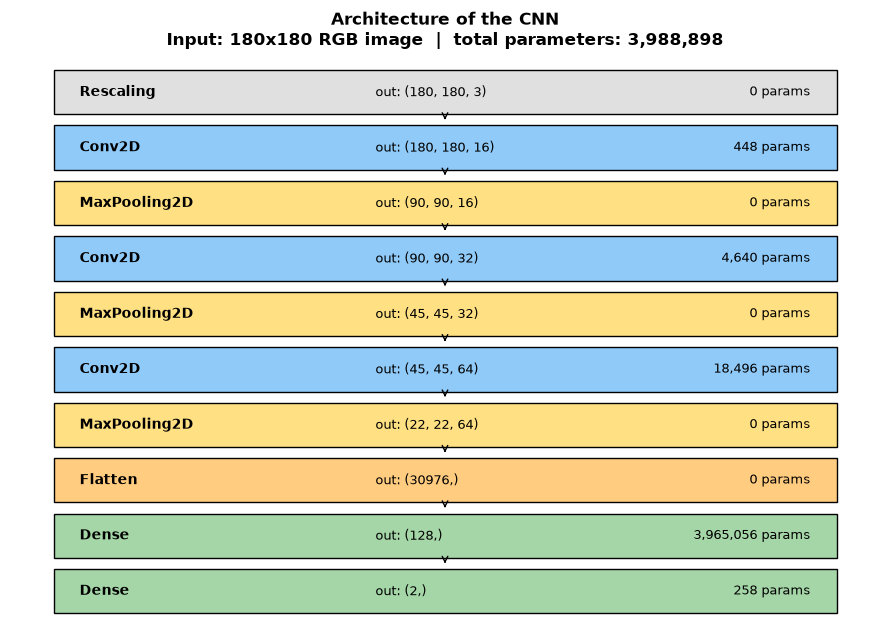

In [13]:
def draw_architecture(model, title):
    colors = {"Rescaling": "#E0E0E0", "Conv2D": "#90CAF9", "MaxPooling2D": "#FFE082",
              "Flatten": "#FFCC80", "Dense": "#A5D6A7"}
    rows = [(layer.__class__.__name__, str(tuple(layer.output.shape[1:])), layer.count_params())
            for layer in model.layers]
    fig, ax = plt.subplots(figsize=(9, 0.55 * len(rows) + 1))
    for i, (kind, shape, params) in enumerate(rows):
        y = len(rows) - i
        ax.add_patch(plt.Rectangle((0.05, y - 0.4), 0.9, 0.8, facecolor=colors.get(kind, "#ECEFF1"), edgecolor="black"))
        ax.text(0.08, y, kind, va="center", fontsize=10, fontweight="bold")
        ax.text(0.42, y, f"out: {shape}", va="center", fontsize=9)
        ax.text(0.92, y, f"{params:,} params", va="center", ha="right", fontsize=9)
        if i < len(rows) - 1:
            ax.annotate("", xy=(0.5, y - 0.45), xytext=(0.5, y - 0.55), arrowprops=dict(arrowstyle="<-"))
    ax.set_xlim(0, 1); ax.set_ylim(0.3, len(rows) + 0.7); ax.axis("off")
    ax.set_title(f"{title}\nInput: {image_h}x{image_w} RGB image  |  total parameters: {model.count_params():,}",
                 fontweight="bold")
    plt.tight_layout(); plt.show()

draw_architecture(model, "Architecture of the CNN")

**Network parameters.**

| Layer | Output | Parameters | Role |
|---|---|---|---|
| `Rescaling(1/255)` | 180×180×3 | 0 | Normalizes the pixels from [0, 255] to [0, 1]. |
| `Conv2D(16, 3×3, ReLU)` | 180×180×16 | 448 | 16 filters of size 3×3: simple local patterns (edges, strokes). |
| `MaxPooling2D(2×2)` | 90×90×16 | 0 | Halves the height and the width, keeps the strongest response. |
| `Conv2D(32, 3×3, ReLU)` | 90×90×32 | 4,640 | 32 filters: textures and motifs. |
| `MaxPooling2D(2×2)` | 45×45×32 | 0 | Halves the height and the width. |
| `Conv2D(64, 3×3, ReLU)` | 45×45×64 | 18,496 | 64 filters: higher-level structures. |
| `MaxPooling2D(2×2)` | 22×22×64 | 0 | Halves the height and the width. |
| `Flatten` | 30,976 | 0 | Turns the 22×22×64 feature maps into one vector. |
| `Dense(128, ReLU)` | 128 | 3,965,056 | Combines all the features to take the decision. |
| `Dense(2)` | 2 | 258 | One score per class: *not a photo* and *photo*. |
| **Total** | | **3,988,898** | All trainable. |

- **Number of parameters.** A convolution has `(3 × 3 × input channels + 1) × filters` parameters: (3×3×3 + 1) × 16 = 448 for the first one. A dense layer has `(inputs + 1) × neurons` parameters: (30,976 + 1) × 128 = 3,965,056. This single dense layer holds **99 % of the weights** of the network.
- **Activation function.** The hidden layers use **ReLU**, `max(0, x)`, which is simple to compute and lets the network learn non-linear relations.
- **Output.** The last layer has no activation function. It returns two scores (called *logits*), and the predicted class is the one with the highest score.

### 1.6 Loss function and optimization algorithm

**Loss function: sparse categorical cross-entropy.** The loss turns the two scores of the last layer into two probabilities (this is what `from_logits=True` asks for) and looks at the probability given to the correct class. The loss is close to 0 when this probability is close to 1, and it becomes large when the network is confident in the wrong class. *Sparse* only means that the labels are integers (0 or 1). With two classes, it is equivalent to the binary cross-entropy. The **error** plotted in Section 2 is the average of this loss over a set of images.

**Optimization algorithm: Adam**, with its default learning rate of 0.001. Training works by gradient descent: for each batch of 32 images, the network computes in which direction each weight should move to make the loss smaller (backpropagation), and moves the weights a little in that direction. The learning rate is the size of that step. Adam improves on this by remembering the direction of the previous updates and by adapting the step size of each weight separately. It converges quickly and needs little tuning.

**Metric: accuracy**, the share of images that are classified correctly.

In [14]:
model.compile(optimizer = 'adam',
              loss = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

### 1.7 Training

Training needs the training set, the test set and the number of epochs. During an epoch the network sees every image of the training set once, and its weights are updated after each batch of 32 images. At the end of each epoch, Keras measures the loss and the accuracy on the test set.

The number of epochs is fixed at 10 and there is no early stopping, so the curves show the complete behaviour of the network.

In [15]:
epochs = 10
history = model.fit(train_set, validation_data=test_set, epochs=epochs)

Epoch 1/10
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 105s 100ms/step - accuracy: 0.8422 - loss: 0.3215 - val_accuracy: 0.8768 - val_loss: 0.2748
Epoch 2/10
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 105s 101ms/step - accuracy: 0.8922 - loss: 0.2421 - val_accuracy: 0.9073 - val_loss: 0.2160
Epoch 3/10
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 104s 100ms/step - accuracy: 0.9175 - loss: 0.1917 - val_accuracy: 0.9125 - val_loss: 0.2254
Epoch 4/10
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 102s 98ms/step - accuracy: 0.9419 - loss: 0.1449 - val_accuracy: 0.9115 - val_loss: 0.2439
Epoch 5/10
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 165s 158ms/step - accuracy: 0.9622 - loss: 0.0970 - val_accuracy: 0.9123 - val_loss: 0.2806
Epoch 6/10
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 367s 352ms/step - accuracy: 0.9783 - loss: 0.0602 - val_accuracy: 0.9103 - val_loss: 0.3616
Epoch 7/10
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 101s 97ms/step - accuracy: 0.9851 - loss: 0.0440 - val_accuracy: 0.9116 - val_loss: 0.3922
Epoch 8/10
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 101s 97ms/step - accur

## 2. Training error, test error and accuracy

The graph shows, epoch after epoch, the **accuracy** on the left and the **error** (loss) on the right, for the training set and for the test set. In the legend, *Validation* is the test set.

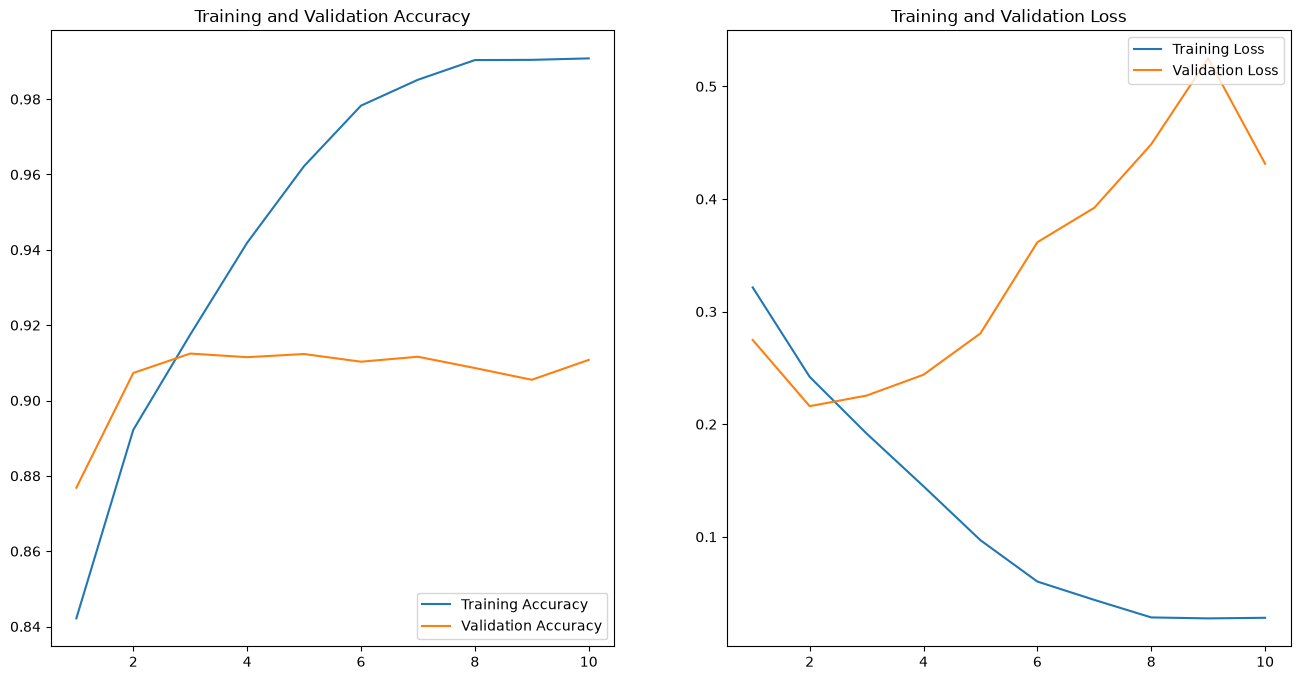

In [16]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(1, epochs + 1)

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

The exact values of the last epoch are hard to read on a graph, so we print them.

In [17]:
best_epoch = int(np.argmin(val_loss)) + 1
print(f"Last epoch ({epochs}): training accuracy = {acc[-1]:.3f} | test accuracy = {val_acc[-1]:.3f}")
print(f"                 training loss     = {loss[-1]:.3f} | test loss     = {val_loss[-1]:.3f}")
print(f"Lowest test loss: {min(val_loss):.3f}, at epoch {best_epoch}")

Last epoch (10): training accuracy = 0.991 | test accuracy = 0.911
                 training loss     = 0.028 | test loss     = 0.431
Lowest test loss: 0.216, at epoch 2


## 3. Analysis of the results: bias and variance

### 3.1 Bias, variance and what they look like on the curves

The error of a model has two sources:

- **Bias** is the error of a model that is **too simple**, or not trained enough: it cannot capture the real patterns. This is **underfitting** (underlearning).
- **Variance** is the error of a model that is **too sensitive to its training set**: it learns the training images, and their noise, by heart instead of learning general rules. This is **overfitting** (overlearning).

A more complex model has less bias but more variance, and the reverse is also true. The goal is the **trade-off** where the error on unseen images is lowest.

| What the curves show | Diagnosis |
|---|---|
| Training error and test error both high | High bias (underfitting) |
| Training error keeps falling, test error stops falling and then rises: the gap grows | High variance (overfitting) |
| Both errors low and close to each other | Good trade-off |


### 3.2 What our curves show

| | Training | Test |
|---|---|---|
| Error (loss) at the last epoch | 0.028 | 0.431 |
| Accuracy at the last epoch | 99.1 % | 91.1 % |
| Lowest test error | | 0.216, at epoch 2 |

The values come from the values printed under the graph and from the training log (Section 1.7).

- **Epochs 1 and 2: both errors fall.** The training error goes from 0.32 to 0.24 and the test error from 0.27 to 0.216, its minimum. The test accuracy rises from 87.7 % to 90.7 %. The network is learning general rules that also work on images it has never seen.
- **From epoch 3: the two curves separate.** The training error keeps falling, down to 0.028, and the training accuracy reaches 99.1 %. The test error does the opposite: it rises almost every epoch, up to 0.525 at epoch 9, and ends at 0.431, twice its minimum. The test accuracy no longer improves: it stays between 90.6 % and 91.3 % and ends at 91.1 %. The final gap between the two accuracies is 8 points.
- **A remark on epoch 1.** At the first epoch the test accuracy (87.7 %) is higher than the training accuracy (84.2 %). This is normal: the training value is an average over the whole epoch, during which the network is still learning, while the test value is measured at the end of the epoch.
- **Comparison with a trivial classifier.** The test set contains 8,339 images, of which 2,023 are photos. A classifier that always answers "not a photo" would therefore be right 75.7 % of the time. Our network reaches 91.1 %, so it has learned real features, but it still misclassifies about one image in eleven.

### 3.3 Diagnosis: low bias, high variance (overfitting)

The curves show the second case of the table in Section 3.1.

- **The bias is low.** The network fits its training set almost perfectly (99.1 %), so its capacity is not the limit.
- **The variance is high.** What the network learns after epoch 2 is specific to the training images and does not transfer to new ones. It is memorizing.

Three characteristics of the experiment explain it:

1. **Too many weights for the amount of data:** 3,988,898 parameters for 33,357 training images, about 120 parameters per image. 99 % of them are in the dense layer that follows `Flatten`.
2. **No regularization:** nothing in the network or in the loss discourages memorization.
3. **Too many epochs:** 8 of the 10 epochs take place after the best point.

The task probably contributes too. Some paintings are visually close to photos, and when no simple rule separates two images, memorizing them one by one is the easiest way for the network to lower its training error.

**Why the error rises while the accuracy stays flat.** After epoch 2, the network becomes more and more confident in its answers, including the wrong ones on the test set. Accuracy only counts right and wrong answers, so it hardly moves. Cross-entropy penalizes a confident wrong answer heavily, so it keeps rising. The error curve is therefore the earlier and more sensitive indicator of overfitting.

**Where the trade-off is.** The best compromise between bias and variance is at **epoch 2**, where the test error is lowest (0.216, test accuracy 90.7 %). After that, the test accuracy only moves between 90.6 % and 91.3 %: the last eight epochs brought almost nothing on new images, while the training score kept improving.

The trade-off has to be improved by reducing the variance, which is the subject of Section 4.

## 4. Methods to improve the bias / variance trade-off

Section 3 shows that our network has a **low bias and a high variance**, so the methods that matter most are the ones that reduce variance.

### 4.1 Methods that reduce variance (overfitting)

Regularization techniques are designed to reduce overfitting. The aim is to prevent the network from memorizing the training set by adjusting itself to its particularities.

| Method | Principle | Application to our network |
|---|---|---|
| **Early stopping** | The test error is monitored during training. Training stops when it has not improved for a given number of epochs (the *patience*), and the weights of the best epoch are restored. | `EarlyStopping(monitor="val_loss", restore_best_weights=True)`, given to `model.fit` with the `callbacks` argument. It costs nothing and even saves training time. |
| **Dropout** | At each training step, a random fraction of the neurons is switched off. The network cannot rely on a few specific neurons and has to spread what it learns. All the neurons are used at prediction time. | A `Dropout(0.2)` layer before `Flatten`. |
| **Data augmentation** | Each training image is randomly transformed at every epoch (horizontal flip, small rotation, zoom). The transformations do not change the class of the image, but the network never sees exactly the same image twice, which makes memorization much harder. | `RandomFlip`, `RandomRotation` and `RandomZoom` layers at the input of the network. They are active only during training. |
| **Smaller network** | Fewer weights means less capacity to memorize. | Replacing `Flatten` with `GlobalAveragePooling2D` reduces the input of the dense layer from 30,976 to 64 values, and its weights from 3,965,056 to 8,320. |
| **Batch normalization** | The outputs of a layer are normalized over each batch. This stabilizes and speeds up training, and adds a slight regularizing effect. | A `BatchNormalization` layer after each convolution. |
| **More training data** | The more examples the network sees, the harder it is to memorize them all. | More labelled images from TouNum, especially photos and paintings. |



### 4.2 Methods that reduce bias (underfitting)

They become useful if the network does not even fit its training set, or if the regularization is too strong:

- a **larger network** (more filters, more layers, more neurons);
- **longer training**, or a better tuned learning rate;
- **less regularization** (lower dropout rate, weaker data augmentation);
- **transfer learning:** reusing the convolutional layers of a network already trained on a very large image dataset and training only a small classification layer on our data. The features are better, which lowers the bias, and few weights are left to learn, which also lowers the variance.

### 4.3 Finding the trade-off

Every method of Section 4.1 trades variance for bias. With too much dropout, too strong an augmentation or too small a network, the model moves to the other side: the training error rises and the model underfits. The right settings (dropout rate, strength of the augmentation, patience) are found by trying several values and keeping the one that gives the **lowest test error**.

Since our network overfits, the order of priority would be:

1. **early stopping**, which immediately gives the model of the best epoch (epoch 2 in our run) instead of the last one;
2. **dropout**, placed just before the layers that hold almost all the weights;
3. **data augmentation**;
4. **`GlobalAveragePooling2D`**, if a gap between the two curves remains.

### 4.4 Applying the improvements

We now apply the first three methods of the priority list to the same network, with the same data, loss and optimizer:

- **data augmentation** at the input: random horizontal flip, rotation (up to 18°) and zoom (up to 10 %), active only during training;
- **dropout** (20 %) just before `Flatten`, where almost all the weights are;
- **early stopping** on the test error, with a patience of 3 epochs: we allow up to 15 epochs, because augmentation makes learning slower, and the weights of the best epoch are kept.

*Note: as in the rest of the notebook, the test set is also the one followed during training, so here it also chooses the epoch. A third, separate set would give a stricter final measure.*

Training took about 24 minutes on a CPU: early stopping ended it after 11 epochs.

In [18]:
data_augmentation = keras.Sequential(
  [
    layers.RandomFlip("horizontal"),                # horizontal inversion
    layers.RandomRotation(0.05),                    # 0.05 x 360 degrees = 18 degrees
    layers.RandomZoom(height_factor=0.1),           # 10% vertical zoom
  ],
  name="data_augmentation"
)

improved_model = Sequential([
    layers.Input(shape=(image_h, image_w, 3)),
    data_augmentation,
    layers.Rescaling(1./255),
    layers.Conv2D(16, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(32, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Dropout(0.2),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(num_classes)
])

improved_model.compile(optimizer='adam',
                       loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                       metrics=['accuracy'])

In [19]:
early_stopping = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

improved_history = improved_model.fit(train_set, validation_data=test_set, epochs=15, callbacks=[early_stopping])

improved_model.save(r"C:\Projet data\modele_photo_improved.keras")
print("Improved model saved")

Epoch 1/15
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 139s 132ms/step - accuracy: 0.8266 - loss: 0.3400 - val_accuracy: 0.8484 - val_loss: 0.3131
Epoch 2/15
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 125s 120ms/step - accuracy: 0.8722 - loss: 0.2792 - val_accuracy: 0.8845 - val_loss: 0.2648
Epoch 3/15
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 124s 119ms/step - accuracy: 0.8887 - loss: 0.2515 - val_accuracy: 0.8990 - val_loss: 0.2401
Epoch 4/15
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 123s 118ms/step - accuracy: 0.8976 - loss: 0.2345 - val_accuracy: 0.9086 - val_loss: 0.2207
Epoch 5/15
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 128s 123ms/step - accuracy: 0.9066 - loss: 0.2180 - val_accuracy: 0.9165 - val_loss: 0.2014
Epoch 6/15
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 126s 120ms/step - accuracy: 0.9126 - loss: 0.2049 - val_accuracy: 0.9087 - val_loss: 0.2285
Epoch 7/15
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 124s 119ms/step - accuracy: 0.9162 - loss: 0.1994 - val_accuracy: 0.9185 - val_loss: 0.2069
Epoch 8/15
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 125s 119ms/step - ac

**The curves of the improved model.** Same graph as Section 2, for the improved model. The grey dashed lines are the test curves of the first model, for comparison, and the dotted line marks the epoch whose weights are kept.

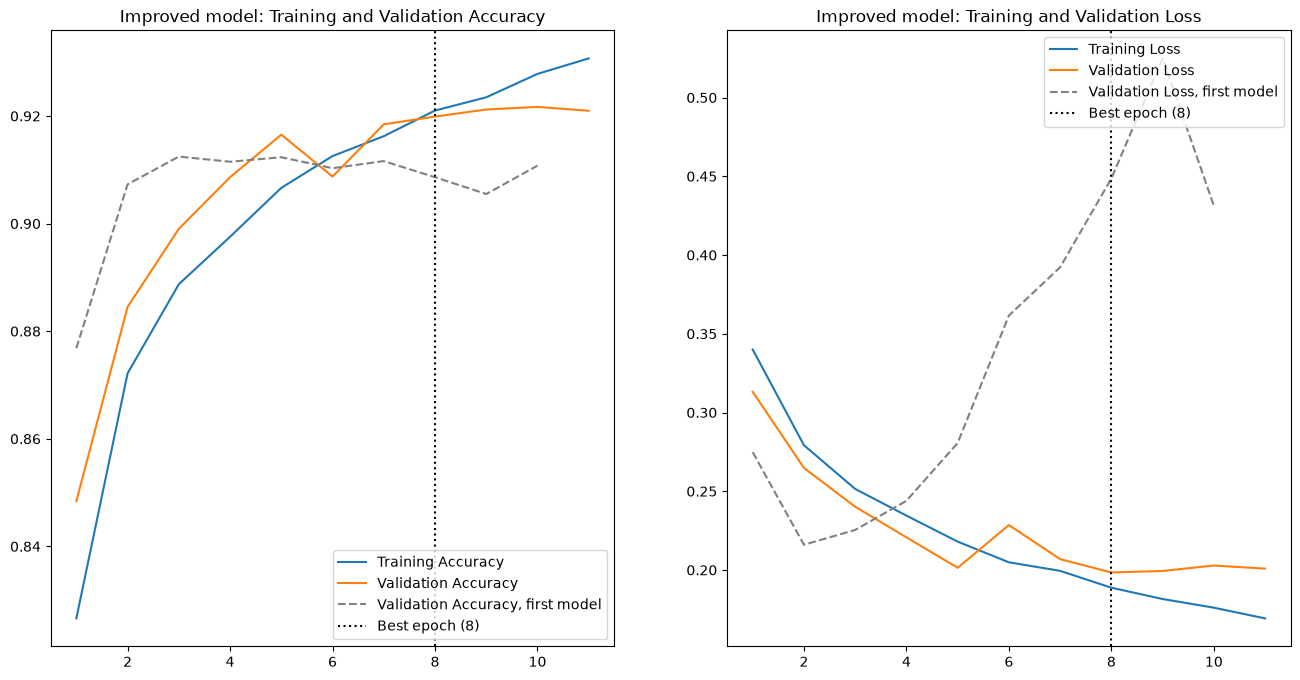

In [20]:
imp_acc = improved_history.history['accuracy']
imp_val_acc = improved_history.history['val_accuracy']
imp_loss = improved_history.history['loss']
imp_val_loss = improved_history.history['val_loss']

imp_epochs_range = range(1, len(imp_loss) + 1)
imp_best_epoch = int(np.argmin(imp_val_loss)) + 1

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(imp_epochs_range, imp_acc, label='Training Accuracy')
plt.plot(imp_epochs_range, imp_val_acc, label='Validation Accuracy')
plt.plot(epochs_range, val_acc, '--', color='grey', label='Validation Accuracy, first model')
plt.axvline(imp_best_epoch, color='black', linestyle=':', label=f'Best epoch ({imp_best_epoch})')
plt.legend(loc='lower right')
plt.title('Improved model: Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(imp_epochs_range, imp_loss, label='Training Loss')
plt.plot(imp_epochs_range, imp_val_loss, label='Validation Loss')
plt.plot(epochs_range, val_loss, '--', color='grey', label='Validation Loss, first model')
plt.axvline(imp_best_epoch, color='black', linestyle=':', label=f'Best epoch ({imp_best_epoch})')
plt.legend(loc='upper right')
plt.title('Improved model: Training and Validation Loss')
plt.show()

And the exact values, side by side:

In [21]:
first_best = best_epoch - 1          # index of the best epoch of the first model
imp_best = imp_best_epoch - 1

rows = [
    ("First model, last epoch",       acc[-1],             val_acc[-1],             loss[-1],             val_loss[-1]),
    ("First model, best epoch",       acc[first_best],     val_acc[first_best],     loss[first_best],     val_loss[first_best]),
    ("Improved model, epoch kept",    imp_acc[imp_best],   imp_val_acc[imp_best],   imp_loss[imp_best],   imp_val_loss[imp_best]),
]
print(f"{'':<30} {'train acc':>9} {'test acc':>9} {'gap':>6} {'train loss':>11} {'test loss':>10}")
for name, a, va, l, vl in rows:
    print(f"{name:<30} {a:>9.3f} {va:>9.3f} {a - va:>6.3f} {l:>11.3f} {vl:>10.3f}")
print(f"\nImproved model: {len(imp_loss)} epochs run, weights of epoch {imp_best_epoch} kept")

                               train acc  test acc    gap  train loss  test loss
First model, last epoch            0.991     0.911  0.080       0.028      0.431
First model, best epoch            0.892     0.907 -0.015       0.242      0.216
Improved model, epoch kept         0.921     0.920  0.001       0.189      0.198

Improved model: 11 epochs run, weights of epoch 8 kept


**What we got.**

| | Training accuracy | Test accuracy | Gap | Training error | Test error |
|---|---|---|---|---|---|
| First model, last epoch (10) | 99.1 % | 91.1 % | 8.0 points | 0.028 | 0.431 |
| First model, best epoch (2) | 89.2 % | 90.7 % | −1.5 points | 0.242 | 0.216 |
| **Improved model, epoch kept (8)** | 92.1 % | **92.0 %** | **0.1 point** | 0.189 | **0.198** |

- **The overfitting is gone.** The gap between training and test accuracy drops from 8 points to 0.1. The two error curves stay close during the 11 epochs: the training error goes from 0.34 to 0.17 and the test error from 0.31 to about 0.20, with no climb back up (the first model went from 0.216 to 0.525).
- **The network is better on new images.** Its best test error is 0.198 against 0.216 for the first model, and its test accuracy is 92.0 % against 91.1 %. It now misclassifies about one image in twelve, instead of one in eleven.
- **Learning is slower but steadier.** The improved model needs 8 epochs to reach its best point instead of 2, because it never sees exactly the same image twice. Early stopping ended the training after epoch 11, three epochs without improvement, and kept the weights of epoch 8.
- **The training accuracy is lower than before (92.1 % against 99.1 %), and that is expected:** it is measured on augmented images with dropout switched on, so the network can no longer memorize its training set.
- **What is left.** The training and test errors are now close (0.189 and 0.198), and the test error has levelled off around 0.20: the remaining error is no longer variance but bias. The next steps would reduce bias without bringing back the overfitting, for example transfer learning (Section 4.2), which should also help with realistic paintings.

In [22]:
model_path = r"C:\Projet data\modele_photo.keras"
model.save(model_path)                      # architecture + trained weights + optimizer state
print("Model saved to", model_path)

Model saved to C:\Projet data\modele_photo.keras


17 test images found in C:\Users\Ihssa\Downloads\pictures
1.jpg            -> not a photo  (87.0%)
2.jpg            -> photo        (68.5%)
3.jpg            -> not a photo  (84.6%)
4.jpg            -> not a photo  (99.8%)
5.jpg            -> not a photo  (100.0%)
dog.JPEG         -> photo        (74.0%)
hotdog.JPEG      -> photo        (81.2%)
images (3).jpe   -> photo        (97.1%)
images (4).jpe   -> photo        (69.9%)
images (5).jpe   -> not a photo  (100.0%)
images (6).jpe   -> not a photo  (99.4%)
monalisa.jpg     -> not a photo  (99.9%)
moodle.png       -> not a photo  (96.1%)
not_photo_0000.jpg -> not a photo  (57.7%)
not_photo_0001.jpg -> photo        (84.3%)
photo_0000.jpg   -> photo        (51.8%)
photo_0001.jpg   -> photo        (95.1%)


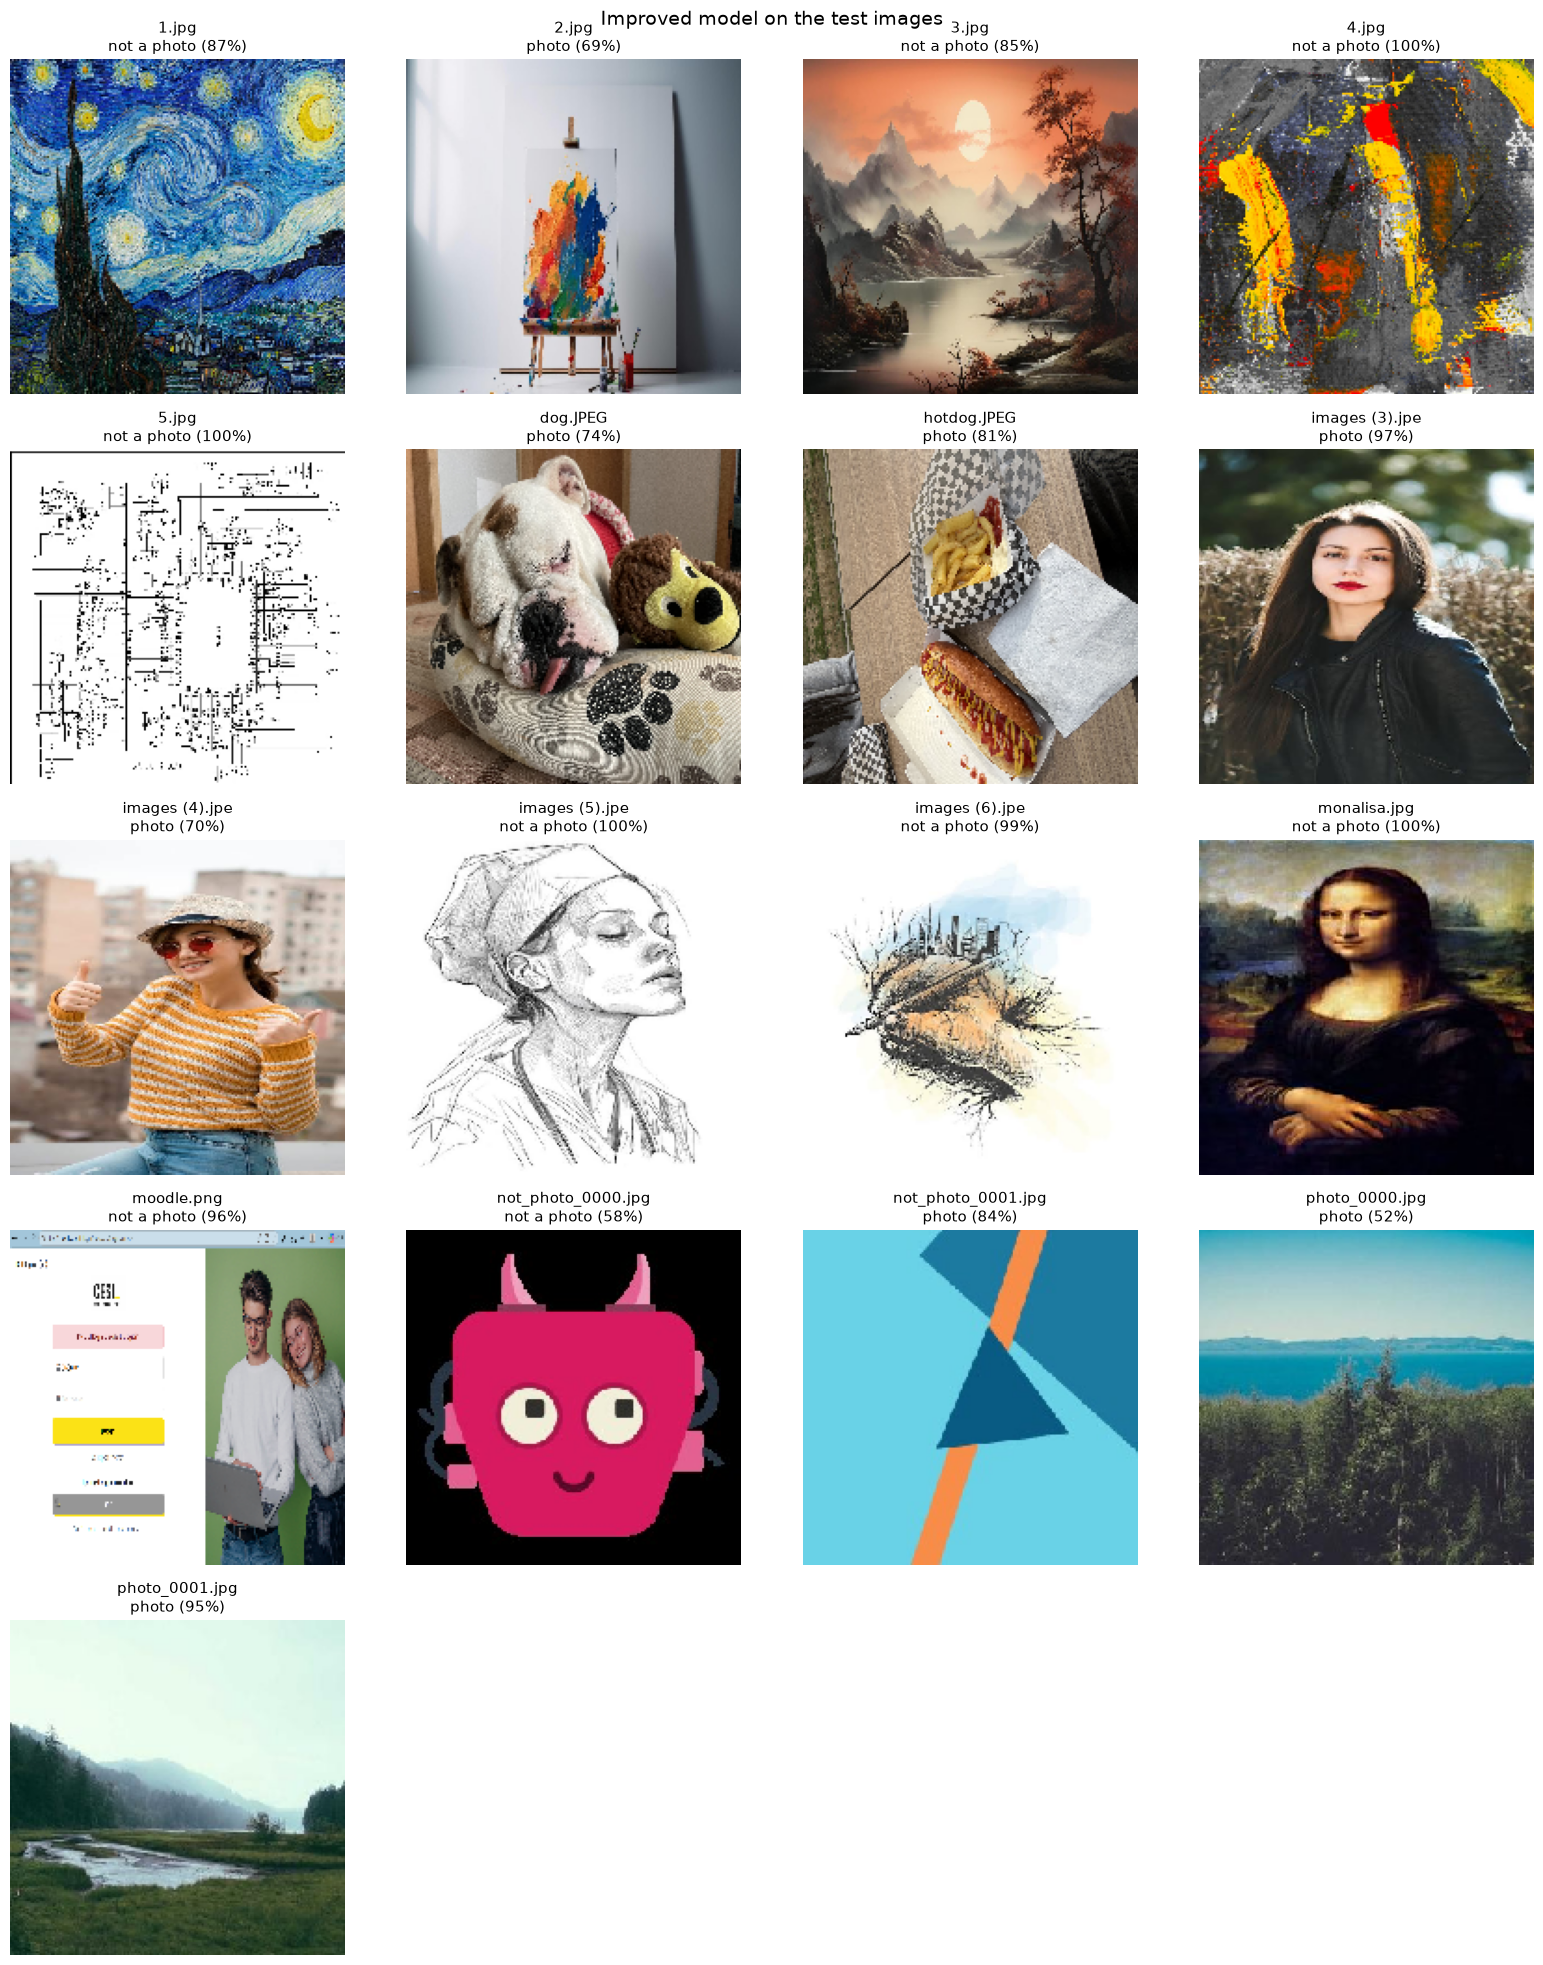

In [28]:
import math

# The improved model of Section 4.4 (run Section 4.4 first: it trains and saves it)
improved_path = pathlib.Path(r"C:\Projet data\modele_photo_improved.keras")
if not improved_path.exists():
    raise FileNotFoundError("modele_photo_improved.keras not found: run Section 4.4 first")
model = tf.keras.models.load_model(improved_path)
image_h, image_w = 180, 180
class_names = ["not a photo", "photo"]

# Test images: every image of the Downloads\pictures folder
test_dir = pathlib.Path.home() / "Downloads" / "pictures"
image_paths = sorted(p for p in test_dir.iterdir()
                     if p.suffix.lower() in (".jpg", ".jpeg", ".jpe", ".png", ".bmp", ".gif"))
print(f"{len(image_paths)} test images found in {test_dir}")

cols = 4
rows = math.ceil(len(image_paths) / cols)                 # the grid adapts to the number of images
plt.figure(figsize=(4 * cols, 4 * rows))
for i, path in enumerate(image_paths):
    img = tf.keras.utils.load_img(path, target_size=(image_h, image_w))
    x = tf.expand_dims(tf.keras.utils.img_to_array(img), 0)
    probs = tf.nn.softmax(model.predict(x, verbose=0)[0]).numpy()
    pred = int(np.argmax(probs))

    print(f"{path.name:<16} -> {class_names[pred]:<12} ({probs[pred]:.1%})")

    plt.subplot(rows, cols, i + 1)
    plt.imshow(np.array(img).astype("uint8"))
    plt.title(f"{path.name}\n{class_names[pred]} ({probs[pred]:.0%})", fontsize=11)
    plt.axis("off")
plt.suptitle("Improved model on the test images", fontsize=14)
plt.tight_layout()
plt.show()

**Test on 17 new images.** Images taken from the web, never seen during training, classified by the improved model.



- **All 17 images are correctly classified**, including the four paintings, the hardest category: even the *Mona Lisa*, a very realistic painting, is rejected at 99.9 %.
- **The model is more hesitant with photos (68.5 % to 97.1 %) than with the other images (84.6 % to 100 %).** This is expected: three training images out of four are not photos, so the network leans towards *not a photo*. `2.jpg` is also a tricky case: a real photo whose subject is a painting.
- 17 images only illustrate the behaviour of the model; the real measure is the test set (8,339 images, 92.0 % accuracy).

In [29]:
# Ensure the trained model is available in the current notebook session
if "model" not in globals():
    model = tf.keras.models.load_model(r"C:\Projet data\modele_photo_improved.keras")

if "class_names" not in globals():
    class_names = ["not a photo", "photo"]

print("Model output:", model.output_shape)
print("Loss function:", model.loss)
print("Classes:", class_names)
print("Loss function:", model.loss)
print("Classes:", class_names)


Model output: (None, 2)
Loss function: <LossFunctionWrapper(<function sparse_categorical_crossentropy at 0x000001F2CE1CC1A0>, kwargs={'from_logits': True, 'ignore_class': None, 'axis': -1, 'label_smoothing': 0.0})>
Classes: ['not a photo', 'photo']
Loss function: <LossFunctionWrapper(<function sparse_categorical_crossentropy at 0x000001F2CE1CC1A0>, kwargs={'from_logits': True, 'ignore_class': None, 'axis': -1, 'label_smoothing': 0.0})>
Classes: ['not a photo', 'photo']
